10/24/2026 Gottlieb

Example: two assets with identical noise to produce a zero-risk trade.

Both assets start at $100. At each step, they receive the same dollar noise. Asset A also gains an extra $1 per share to demonstrate arbitrage.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
init_price = 100.0
noise = np.array([-3.0, 2.0, -4.0, 1.0, 3.0])
extra_growth = 1.0

asset_a = np.array([init_price])
asset_b = np.array([init_price])

for i in range(len(noise)):
    asset_a = np.append(asset_a, asset_a[i] + noise[i] + extra_growth)
    asset_b = np.append(asset_b, asset_b[i] + noise[i])

data = pd.DataFrame({'Asset A': asset_a, 'Asset B': asset_b})

data

,Asset A,Asset B
0,100.0,100.0
1,98.0,97.0
2,101.0,99.0
3,98.0,95.0
4,100.0,96.0
5,104.0,99.0


Contruct the arbitrage: long one share of asset A and short one share of B


In [3]:
long_pnl = asset_a - asset_a[0]
short_pnl = asset_b[0] - asset_b
portfolio_pnl = long_pnl + short_pnl

data["Long A PnL"] = long_pnl
data["Short B PnL"] = short_pnl
data["Portfolio PnL"] = portfolio_pnl

data

,Asset A,Asset B,Long A PnL,Short B PnL,Portfolio PnL
0,100.0,100.0,0.0,0.0,0.0
1,98.0,97.0,-2.0,3.0,1.0
2,101.0,99.0,1.0,1.0,2.0
3,98.0,95.0,-2.0,5.0,3.0
4,100.0,96.0,0.0,4.0,4.0
5,104.0,99.0,4.0,1.0,5.0


Simulating two cointegrated series

Random Walk: $X_t = X_{t-1} + \epsilon_t$

Mean-Reverting Gap: $z_t = \phi z_{t-1} + \eta_t$

Construction: $Y_t = bX_t + z_t$

In [4]:
np.random.seed(42)

n = 500
b = 1.5
phi = 0.8

x_noise = np.random.choice([-1,1], size=n)
z_noise = np.random.choice([-1,1], size=n)

X = np.zeros(n)
z = np.zeros(n)
X[0] = 100

for t in range(1, n):
    X[t] = X[t-1] + x_noise[t]
    z[t] = phi * z[t-1] + z_noise[t]

Y = b * X + z
gap = Y - b * X

data = pd.DataFrame({"X": X, "Y": Y, "Gap": gap})
data.head()


,X,Y,Gap
0,100.0,150.000,0.000
1,101.0,150.500,-1.000
2,100.0,148.200,-1.800
3,99.0,148.060,-0.440
4,98.0,145.648,-1.352


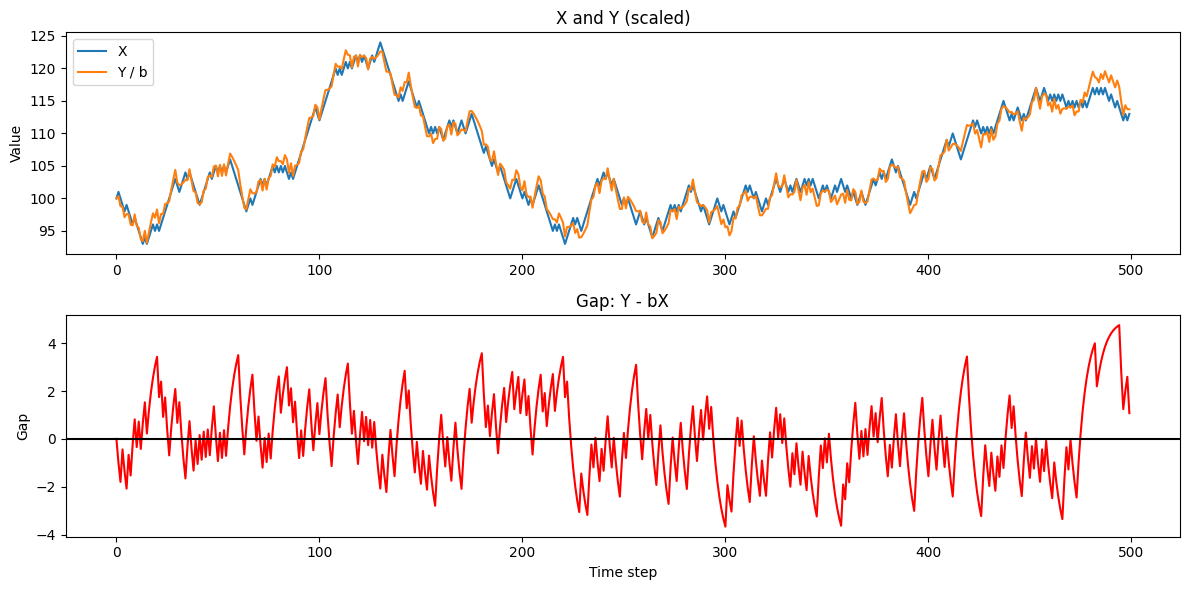

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].plot(X, label="X")
axes[0].plot(Y / b, label="Y / b")
axes[0].set_title("X and Y (scaled)")
axes[0].set_ylabel("Value")
axes[0].legend()

axes[1].plot(gap, c="r")
axes[1].axhline(0, c="k")
axes[1].set_title("Gap: Y - bX")
axes[1].set_xlabel("Time step")
axes[1].set_ylabel("Gap")

plt.tight_layout()
plt.show()

Test the gap for stationarity using an Augmented-Dickey Fuller (ADF)

The ADF test has the following hypotheses:
- $H_0$: the series has a unit root (non-stationary)
- $H_1$: the series does not have a unit root (stationary)

Prediction: At the 5% significance level, we predict that we will fail to reject $H_0$ for $X$ and $Y$. We predict that we will reject $H_0$ for the gap $Y - bX$, because this was deliberately made to be mean-reverting.

In [6]:
from statsmodels.tsa.stattools import adfuller

In [7]:
def run_adf(series, name):
    result = adfuller(series)
    test_stat = result[0]
    p_val = result[1]

    print(f"Series: {name}")
    print(f"ADF test statistic: {test_stat:.5f}")
    print(f"p-value: {p_val:.5f}")

    if p_val < 0.05:
        print("Reject null hypothesis: series is stationary")
    else:
        print("Fail to reject null hypothesis: series is non-stationary\n")

run_adf(X, "X")
run_adf(Y, "Y")
run_adf(gap, "Gap (Y - bX)")

Series: X
ADF test statistic: -1.57864
p-value: 0.49432
Fail to reject null hypothesis: series is non-stationary

Series: Y
ADF test statistic: -1.67873
p-value: 0.44210
Fail to reject null hypothesis: series is non-stationary

Series: Gap (Y - bX)
ADF test statistic: -7.46139
p-value: 0.00000
Reject null hypothesis: series is stationary


Previously, we tested the gap using the true value $b=1.5$ that we used to create the data. In practice, we do not know the cointegrating relationship in advance.

The Engle-Granger test first estimates an OLS regression model on two non-stationary time series. Then it tests the stationarity of the estimated regression residual. The Engle-Granger test has the following hypothesis:
- $H_0$: The two time series are not cointegrated
- $H_1$: The two time series are cointegrated

Where cointegration is being defined as a statistical property in which two or more non-stationary variables share a long-term equilibrium relationship. Even though the individual series drift or wander randomly, a specific linear combination of them remain stationary.

In [8]:
from statsmodels.tsa.stattools import coint

In [9]:
coint_stat, p_val, crit_vals = coint(Y, X)

print(f"Cointegration test statistic: {coint_stat:.5f}")
print(f"p-value: {p_val:.5f}")
print(f"1% critical value: {crit_vals[0]:.5f}")
print(f"5% critical value: {crit_vals[1]:.5f}")
print(f"10% critical value: {crit_vals[2]:.5f}\n")

if p_val < 0.05:
    print("Reject null hypothesis: the two series are cointegrated")
else:
    print("Fail to reject null hypothesis: the two series are not cointegrated")

Cointegration test statistic: -7.50974
p-value: 0.00000
1% critical value: -3.91852
5% critical value: -3.34840
10% critical value: -3.05296

Reject null hypothesis: the two series are cointegrated
